<a href="https://colab.research.google.com/github/jorgecaraveobalderas-beep/Class-Files/blob/main/Sesion12_Evaluacion_Analisis_Descriptivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Evaluación — Análisis Descriptivo de Datos

**Entrega individual**

- **Nombre:** Jorge Alberto Caraveo Balderas
- **Matrícula:** 274702

Esta evaluación aplica los cuatro bloques de la Sesión 12 (tendencia central, dispersión, forma, visualización) a un dataset que no se trabajó en clase: **NYC Airbnb 2019**, específicamente la columna `price`.

| | |
|---|---|
| **Tiempo estimado** | 45-55 min |
| **Entrega** | Notebook completo (.ipynb) con todas las celdas ejecutadas, subido a Moodle |
| **Puntaje total** | 100 puntos (ver rúbrica al final) |

Cada actividad tiene su propia pregunta de conclusión — esas respuestas se califican como parte de la actividad correspondiente, no concentradas en la reflexión final. Comenta tu código donde tomes una decisión (por ejemplo, cuántos bins usar en un histograma, o qué columna comparar) — el comentario también forma parte del puntaje.

## Preparación

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = 'https://raw.githubusercontent.com/pjournal/boun01g-data-mine-r-s/gh-pages/Assignment/AB_NYC_2019.csv'
df = pd.read_csv(url)
df[['name', 'neighbourhood_group', 'room_type', 'price']].head()

,name,neighbourhood_group,room_type,price
0,Clean & quiet apt home by the park,Brooklyn,Private room,149
1,Skylit Midtown Castle,Manhattan,Entire home/apt,225
2,THE VILLAGE OF HARLEM....NEW YORK !,Manhattan,Private room,150
3,Cozy Entire Floor of Brownstone,Brooklyn,Entire home/apt,89
4,Entire Apt: Spacious Studio/Loft by central park,Manhattan,Entire home/apt,80


---
## Actividad 1 — Tendencia central (20 pts)

In [2]:
# 1.1 — Calcula la media, mediana y moda de la columna 'price'.

#Calcular con las funciones vistas en el notebook de practica

print('Media:  ', df['price'].mean())
print('Mediana:', df['price'].median())
print('Moda:   ', df['price'].mode())



Media:   152.7206871868289
Mediana: 106.0
Moda:    0    100
Name: price, dtype: int64


**1.2 — Conclusión (responde aquí en Markdown):**

¿La media y la mediana de `price` se parecen o divergen mucho? Con base en lo que viste en clase sobre `Income`, ¿qué te sugiere esa divergencia (o esa similitud) sobre la presencia de valores extremos en esta columna?

_Tu respuesta:_

**La media y la mediana de la columna "price" sí divergen de manera signifactiva, ya que la diferencia entre ambos es de alrededor de un 45%. Esta divirgencia indica una distribución sesgada hacia la derecha (asimetría positiva) provocado por valores altos dentro de la columna(outliers), al igual que lo que sucedió en el ejercicio anterior con la columna "Income"sí**


---
## Actividad 2 — Dispersión (20 pts)

In [3]:
# 2.1 — Calcula el rango, la varianza, la desviación estándar y el IQR (Q1, Q3, IQR) de 'price'.

#Calcular con las funciones vistas en el notebook de practica

rango = df['price'].max() - df['price'].min()
print('Rango:', rango)
varianza = df['price'].var()
print(f'Varianza: {varianza:.2f}')
desviacion = df['price'].std()
print(f'Desviación estándar: {desviacion:.2f}')

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

print('Q1:', Q1)
print('Q3:', Q3)
print('IQR:', IQR)

# Calcular el valor maximo para la conclusion de 2.2

maximo = df['price'].max()
print("El precio maximo es", maximo)

Rango: 10000
Varianza: 57674.03
Desviación estándar: 240.15
Q1: 69.0
Q3: 175.0
IQR: 106.0
El precio maximo es 10000


**2.2 — Conclusión (responde aquí en Markdown):**

Compara el rango contra el IQR de `price`. ¿Cuál de los dos te parece más representativo de la dispersión "típica" de los precios, y por qué? (revisa el valor máximo de la columna antes de responder)

_Tu respuesta:_


**El IQR es la medida adecuada porque es una métrica robusta frente a outliers. Muestra que la variación típica entre los alojamientos estándar es de apenas 106, mientras que el rango transmite la falsa idea de que la dispersión es de miles.**

**El valor máximo de la columna es 10,000, siendo igual que el rango, por lo que potencialmente existe un error o un dato faltante en la columna "price", ya que el valor menor es 0, lo cual resulta sin sentido ya que al tratarse de un servicio de renta, esto sugiere como si fuese gratis, lo cual no es correcto.**


---
## Actividad 3 — Forma (20 pts)

In [4]:
# 3.1 — Calcula la asimetría (skew) y la curtosis (kurt) de 'price'.

#Calcular con las funciones vistas en el notebook de practica

Asimetria = df['price'].skew()
print(f'Asimetria: {Asimetria:.2f}')
Curtosis = df['price'].kurt()
print(f'Curtosis: {Curtosis:.2f}')



Asimetria: 19.12
Curtosis: 585.67


**3.2 — Conclusión (responde aquí en Markdown):**

Compara estos valores con los de `Income` que viste en clase (asimetría 6.76, curtosis 159.6 con el outlier incluido). ¿Cómo se comparan los de `price`? ¿Qué relación esperarías entre estos valores y lo que vas a encontrar en la próxima etapa del curso (Datos Atípicos)?

_Tu respuesta:_

**Los valores de price muestran una asimetría de 19.12 y una curtosis de 585.67, resultando considerablemente más altos que los de Income (6.76 y 159.6) esto indica que la columna price está todavía más distorsionada por la presencia de valores extremos altos en su distribución.**

**En la próxima etapa de datos atípicos, se esperaría detectar una gran cantidad de outliers. Por lo tanto, será necesario realizar un profiling para corregir el sesgo y evitar que estos datos afecten el análisis.**

---
## Actividad 4 — Visualización (30 pts)

<Axes: title={'center': 'Distribución de precios'}, ylabel='Frequency'>

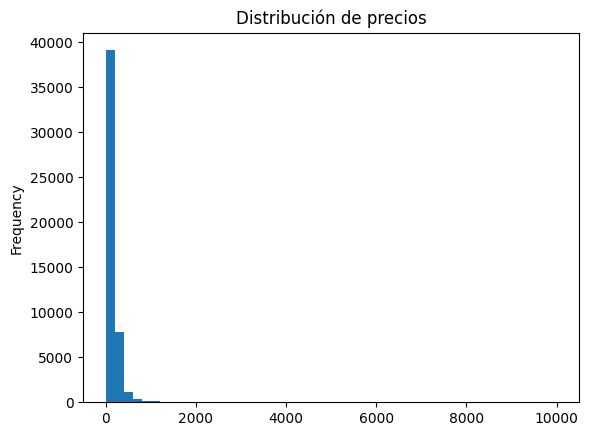

In [5]:
# 4.1 — Construye un histograma de 'price' con .plot(kind='hist').
# Elige un número de bins que te parezca razonable y comenta por qué lo elegiste.

#Calcular con las funciones vistas en el notebook de practica

df['price'].plot(kind='hist', bins=50, title='Distribución de precios')
# Dado que los precios van de 0 a 10,000, utilizar 50 bins crea intervalos de 200 USD por barra,
# esto permite abarcar todo el rango de datos manteniendo que estos sean fácil de interpretar


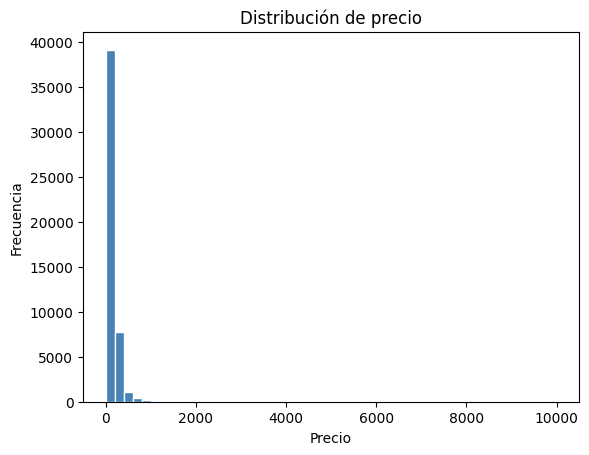

In [6]:
# 4.2 — Construye el mismo histograma con matplotlib.pyplot directamente (plt.hist()),
# agregando título y etiquetas en los ejes.

#Calcular con las funciones vistas en el notebook de practica

plt.hist(df['price'], bins=50, color='steelblue', edgecolor='white')
plt.title('Distribución de precio')
plt.xlabel('Precio')
plt.ylabel('Frecuencia')
plt.show()


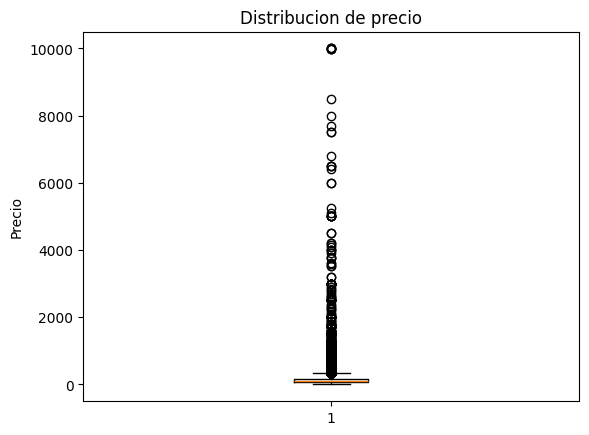

In [7]:
# 4.3 — Construye un boxplot de 'price' (con .plot(kind='box') o plt.boxplot()).

#Calcular con las funciones vistas en el notebook de practica

plt.boxplot(df['price'])
plt.title('Distribucion de precio')
plt.ylabel('Precio')
plt.show()

**4.4 — Conclusión (responde aquí en Markdown):**

Describe lo que observas en el histograma y el boxplot de `price`. ¿Los outliers son visibles en ambos gráficos? ¿En cuál se distinguen mejor? Relaciona tu respuesta con los valores de asimetría y curtosis que calculaste en la Actividad 3.

_Tu respuesta:_

**El histograma muestra una concentración masiva de datos agrupados en la zona de precios bajos (0 a 200) con una cola que se extiende hacia los 10,000. Por su parte, el boxplot presenta una caja completamente "aplastada" en la base debido a que el 50% de los datos se ubica entre por debajo de los precios de 200.**

**Aunque los datos atípicos distorsionan ambos gráficos, se distinguen mucho mejor en el boxplot. En el histograma, las frecuencias de los precios altos son tan bajas que las barras resultan casi invisibles. En cambio, el boxplot dibuja cada outlier como un punto individual, mostrando con claridad la columna de valores que se dispara hacia arriba**

**La asimetría de 19.12 se refleja en la fuerte concentración de datos al inicio. Por otra parte, la curtosis de 585.67 explica el pico extremo en la primera barra del histograma, así como la enorme cantidad de valores atípicos que se aprecian por encima de la caja en el boxplot**

---
## Reflexión final (10 pts)

Con base en las 4 actividades anteriores: si tuvieras que explicarle a alguien que no ha visto este dataset por qué el precio "promedio" de $152.72 puede ser engañoso, ¿qué le dirías, usando al menos dos de las medidas que calculaste?

_Tu respuesta:_

**Le explicaría que precio promedio de 152.72 es engañoso porque está inflado por valores extremadamente altos. La mediana de 106.00 demuestra que la mitad de las propiedades cuestan 106.00 o menos, revelando que la mayoría de la oferta es considerablemente más económica que la media.**
**Por su parte, el rango de 10,000.00 y la alta asimetría de 19.12 confirman la presencia de una cola larga a la derecha que distorsiona el promedio, haciendo de la mediana la medida más representativa para este dataset.**

---
## Rúbrica de evaluación

| Actividad | Puntos | Criterio |
|---|---|---|
| 1. Tendencia central | 20 | Calcula correctamente media, mediana, moda; la conclusión (1.2) conecta la divergencia con la presencia de outliers, no es una afirmación aislada |
| 2. Dispersión | 20 | Calcula correctamente rango, varianza, std, IQR; la conclusión (2.2) justifica cuál medida es más representativa con evidencia del propio cálculo |
| 3. Forma | 20 | Calcula correctamente asimetría y curtosis; la conclusión (3.2) compara explícitamente contra el caso de `Income` visto en clase |
| 4. Visualización | 30 | Histograma y boxplot correctamente construidos (ambas versiones: `.plot()` y `plt.`); código comentado justificando decisiones (ej. bins); la conclusión (4.4) conecta lo visual con los estadísticos de la Actividad 3 |
| Reflexión final | 10 | La explicación usa al menos dos medidas concretas, no es una respuesta genérica |
| **Total** | **100** | |